## EXPÉRIENCE A : comparaison des architectures ANN (ANN-1 à ANN-5)
#### Objectif :  evaluer si la profondeur ou la largeur du réseau classe mieux l'occupation du sol 

#### Principe directeur : une seule chose change d'un modèle à l'autre, l'architecture.


In [39]:
# importation des données propres

import os
import time
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
 
import keras
from keras import layers
 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, matthews_corrcoef)

Initialisation des parametres et definition des fonctions utiles pour cette experience ainsi que les autres

In [4]:
data= pd.read_csv("donnees_propres.csv", sep=",")
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  1000 non-null   int64  
 1   Classes1            1000 non-null   int64  
 2   class_name          1000 non-null   object 
 3   Classes1_origine    1000 non-null   int64  
 4   class_name_origine  1000 non-null   object 
 5   B1                  1000 non-null   float64
 6   B2                  1000 non-null   float64
 7   B3                  1000 non-null   float64
 8   B4                  1000 non-null   float64
 9   B5                  1000 non-null   float64
 10  B6                  1000 non-null   float64
 11  B7                  1000 non-null   float64
 12  B8                  1000 non-null   float64
 13  B9                  1000 non-null   float64
 14  B10                 1000 non-null   float64
 15  NDVI                1000 non-null   float64
 16  EVI    

In [6]:
SEED_PARTITION = 42          # graine du découpage train / validation / test (fixe)
GRAINES = [0, 1, 2, 3, 4]    # 5 initialisations des poids par architecture 
                             
TAUX_APPRENTISSAGE = 1e-3    # taux d'apprentissage d'Adam 
TAILLE_LOT = 32              
EPOCHS_MAX = 200             
PATIENCE = 20                # arrêt si la perte de validation ne s'améliore plus pendant 20 epochs
TAUX_DROPOUT = 0.2  

DOSSIER_SORTIE = "resultats/experience_A"
 

In [7]:
 
# Variables d'entrée : 10 bandes + 9 indices ; Les coordonnées seront introduites dans l'experience F
BANDES = [f"B{i}" for i in range(1, 11)]
INDICES = ["NDVI", "EVI", "NDRE", "SAVI", "NDMI", "NDWI", "MSI", "BSI", "BI"]
VARIABLES = BANDES + INDICES
 

X = data[VARIABLES].to_numpy(dtype="float32")
encodeur = LabelEncoder()                       # transforme les noms de classes en entiers 0..7
y = encodeur.fit_transform(data["class_name"])
NOMS_CLASSES = list(encodeur.classes_)
N_CLASSES = len(NOMS_CLASSES)
 
print(f"{X.shape[0]} observations, {X.shape[1]} variables, {N_CLASSES} classes")
print(pd.Series(data["class_name"]).value_counts().to_string())
 
# Découpage train / validation / test (70 / 15 / 15) , stratifié

idx = np.arange(len(y))
idx_train, idx_temp = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED_PARTITION)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, stratify=y[idx_temp],
                                     random_state=SEED_PARTITION)
 
# On sauvegarde les partitions pour pouvoir réutiliser EXACTEMENT les mêmes par la suite
partitions = pd.DataFrame({"id": data["id"], "ensemble": ""})
partitions.loc[idx_train, "ensemble"] = "train"
partitions.loc[idx_val, "ensemble"] = "validation"
partitions.loc[idx_test, "ensemble"] = "test"           # reservé a l'evaluation finale du modele 
partitions.to_csv(os.path.join(DOSSIER_SORTIE, "partitions.csv"), index=False)
 
print("\nEffectifs par classe et par ensemble :")
print(pd.crosstab(data["class_name"], partitions["ensemble"]).to_string())

#  Standardisation sur l'entraînement pour eviter la fuite de données
normaliseur = StandardScaler().fit(X[idx_train])         # le normaliseur apprend les parametres sur le train puis l'applique afin d'eviter une fuite de donnée
X_train, y_train = normaliseur.transform(X[idx_train]), y[idx_train]
X_val, y_val = normaliseur.transform(X[idx_val]), y[idx_val]
 
# Définition des 5 architectures
# Toutes : entrée = 19 variables, couches cachées ReLU, sortie softmax à 8 neurones .
ARCHITECTURES = {
    "ANN-1": [32],
    "ANN-2": [64, 32],
    "ANN-3": [128, 64, 32],
    "ANN-4": [128, 128, 64, 32],
    "ANN-5": [128, 64, 32],      # = ANN-3 + Batch Normalization + Dropout 
}
 
 
def construire_modele(nom, couches):
    """Construit un réseau dense (MLP) à partir de la liste des neurones par couche cachée."""
    modele = keras.Sequential(name=nom.replace("-", "_"))
    modele.add(keras.Input(shape=(len(VARIABLES),)))
    for n in couches:
        if nom == "ANN-5":
            # Ordre : Dense -> BatchNorm -> activation
            modele.add(layers.Dense(n))
            modele.add(layers.BatchNormalization())
            modele.add(layers.Activation("relu"))
        else:
            modele.add(layers.Dense(n, activation="relu"))
    if nom == "ANN-5":
        # Dropout placé APRÈS la dernière BatchNorm 
        modele.add(layers.Dropout(TAUX_DROPOUT))
    modele.add(layers.Dense(N_CLASSES, activation="softmax"))
 
    # Perte : entropie croisée multiclasse ; « sparse » car y contient des entiers (0..7)
    modele.compile(optimizer=keras.optimizers.Adam(learning_rate=TAUX_APPRENTISSAGE) ,    # on utilise l'optimiseur adam,
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modele
 
def nb_parametres_entrainables(modele):
    return int(sum(np.prod(w.shape) for w in modele.trainable_weights))
 
 
# Vérification : nombre de paramètres de chaque architecture
for nom, couches in ARCHITECTURES.items():
    m = construire_modele(nom, couches)
    print(f"{nom} : {' -> '.join(map(str, [len(VARIABLES)] + couches + [N_CLASSES]))} "
          f"| {nb_parametres_entrainables(m):,} paramètres entraînables".replace(",", " "))
 
 


1000 observations, 19 variables, 8 classes
class_name
Rubber and Other Crops                  601
Savannas                                102
Coffee and Cocoa                        101
Forest                                   78
Human Infrastructure and Settlements     59
Wetlands                                 27
Water Bodies                             24
Bare Soil and Rock Outcrops               8

Effectifs par classe et par ensemble :
ensemble                              test  train  validation
class_name                                                   
Bare Soil and Rock Outcrops              2      5           1
Coffee and Cocoa                        15     71          15
Forest                                  11     55          12
Human Infrastructure and Settlements     9     41           9
Rubber and Other Crops                  90    421          90
Savannas                                16     71          15
Water Bodies                             3     17         

Les données ont été réparties en trois sous-ensembles : 70 % pour l'entraînement, 15 % pour la validation et 15 % pour le test. La méthode de stratification (stratify) a été utilisée afin de conserver, autant que possible, les proportions des différentes classes dans chaque sous-ensemble. Toutefois, le jeu de données présente un déséquilibre important entre les classes.
Les cinq architectures utilisent 19 variables d'entrée et huit neurones de sortie, correspondant aux huit classes à prédire. A titre d'illustration l'ANN-1 constitue l'architecture la plus simple, avec une seule couche cachée de 32 neurones et 904 paramètres entraînables. L'ANN-2 comporte deux couches cachées de largeur 64 et 32 neurones, pour un total de 3 624 paramètres.

L'ANN-5 reprend l'architecture de l'ANN-3, à laquelle sont ajoutées deux techniques de régularisation : la normalisation par lots (Batch Normalization) et le Dropout. La normalisation par lots contribue à stabiliser les activations au cours de l'apprentissage, tandis que le Dropout désactive temporairement une partie des neurones pendant l'entraînement afin de limiter la dépendance excessive du réseau à certaines connexions. Ces mécanismes visent à améliorer la généralisation du modèle et à réduire le risque de surapprentissage


In [23]:
#le kappa est contesté pour l'évaluation des cartes  d'ou le retrait dans nos metriques(Foody, 2020)

def calculer_metriques(y_vrai, y_pred):
    return {   
        "accuracy": accuracy_score(y_vrai, y_pred),
        "precision_macro": precision_score(y_vrai, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_vrai, y_pred, average="macro", zero_division=0),
        "f1_pondere": f1_score(y_vrai, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_vrai, y_pred),
    }

#  Entraînement : 5 architectures x 5 graines, mêmes données, mêmes conditions
resultats = []        # une ligne par (architecture, graine)
historiques = {}      # courbes d'apprentissage, pour les graphiques
f1_par_classe = {}    # F1 de chaque classe sur la validation
 
for nom, couches in ARCHITECTURES.items():
    for graine in GRAINES:
        keras.utils.set_random_seed(graine)          # même initialisation reproductible pour chaque graine
        modele = construire_modele(nom, couches)
 
        # Arrêt anticipé : on surveille la perte de validation et on garde les meilleurs poids
        arret = keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                              restore_best_weights=True)
        debut = time.perf_counter()
        hist = modele.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=EPOCHS_MAX, batch_size=TAILLE_LOT,
                          callbacks=[arret], verbose =0)   # on sature pas le terminal avec l'historique
        duree = time.perf_counter() - debut
 
        # Prédiction = classe de plus forte probabilité softmax
        pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)
        pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
        m_train = calculer_metriques(y_train, pred_train)
        m_val = calculer_metriques(y_val, pred_val)
 
        resultats.append({
            "modele": nom, "graine": graine,
            "parametres": nb_parametres_entrainables(modele),
            "epochs_effectuees": len(hist.history["loss"]),
            "meilleure_epoch": int(np.argmin(hist.history["val_loss"])) + 1,
            "temps_s": duree,
            "perte_val": float(np.min(hist.history["val_loss"])),
            **{f"val_{k}": v for k, v in m_val.items()},
            "train_f1_macro": m_train["f1_macro"],
            # Écart entraînement - validation : indicateur de surapprentissage
            "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],
        })
        historiques[(nom, graine)] = hist.history
        f1_par_classe[(nom, graine)] = f1_score(y_val, pred_val, average=None,
                                                labels=range(N_CLASSES), zero_division=0)
        print(f"{nom} | graine {graine} | {len(hist.history['loss'])} epochs | "
              f"Macro-F1 val = {m_val['f1_macro']:.3f} | {duree:.1f} s")
 
resultats = pd.DataFrame(resultats)
resultats.to_csv(os.path.join(DOSSIER_SORTIE, "resultats_detailles.csv"), index=False)
 
# 7. Tableau récapitulatif : moyenne ± écart-type sur les 5 graines (sur la VALIDATION)
colonnes = ["val_f1_macro", "val_accuracy", "val_precision_macro", "val_recall_macro",
            "val_f1_pondere", "val_mcc", "ecart_f1_train_val",
            "meilleure_epoch", "temps_s"]
recap = resultats.groupby("modele")[colonnes].agg(["mean", "std"])
recap.insert(0, ("parametres", ""), resultats.groupby("modele")["parametres"].first())
 
# Version lisible : « moyenne ± écart-type »
tableau = pd.DataFrame(index=recap.index)
tableau["Paramètres"] = recap[("parametres", "")]
for c in colonnes:
    dec = 0 if c in ("meilleure_epoch",) else (1 if c == "temps_s" else 3)
    tableau[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap[(c, "mean")], recap[(c, "std")])]
tableau.to_csv(os.path.join(DOSSIER_SORTIE, "recapitulatif_architectures.csv"))

display(tableau)                



ANN-1 | graine 0 | 76 epochs | Macro-F1 val = 0.340 | 84.4 s
ANN-1 | graine 1 | 85 epochs | Macro-F1 val = 0.328 | 63.9 s
ANN-1 | graine 2 | 75 epochs | Macro-F1 val = 0.342 | 45.6 s
ANN-1 | graine 3 | 133 epochs | Macro-F1 val = 0.349 | 42.5 s
ANN-1 | graine 4 | 131 epochs | Macro-F1 val = 0.300 | 58.2 s
ANN-2 | graine 0 | 67 epochs | Macro-F1 val = 0.348 | 22.0 s
ANN-2 | graine 1 | 57 epochs | Macro-F1 val = 0.343 | 19.3 s
ANN-2 | graine 2 | 48 epochs | Macro-F1 val = 0.320 | 15.6 s
ANN-2 | graine 3 | 60 epochs | Macro-F1 val = 0.332 | 18.3 s
ANN-2 | graine 4 | 65 epochs | Macro-F1 val = 0.347 | 20.6 s
ANN-3 | graine 0 | 54 epochs | Macro-F1 val = 0.385 | 18.4 s
ANN-3 | graine 1 | 38 epochs | Macro-F1 val = 0.351 | 13.1 s
ANN-3 | graine 2 | 38 epochs | Macro-F1 val = 0.348 | 15.1 s
ANN-3 | graine 3 | 46 epochs | Macro-F1 val = 0.377 | 16.9 s
ANN-3 | graine 4 | 31 epochs | Macro-F1 val = 0.324 | 11.5 s
ANN-4 | graine 0 | 34 epochs | Macro-F1 val = 0.347 | 12.8 s
ANN-4 | graine 1 | 37 

,Paramètres,val_f1_macro,val_accuracy,val_precision_macro,val_recall_macro,val_f1_pondere,val_mcc,ecart_f1_train_val,meilleure_epoch,temps_s
modele,,,,,,,,,,
ANN-1,904,0.332 ± 0.019,0.641 ± 0.013,0.423 ± 0.068,0.337 ± 0.015,0.568 ± 0.015,0.306 ± 0.031,0.101 ± 0.041,80 ± 29,58.9 ± 16.8
ANN-2,3624,0.338 ± 0.012,0.639 ± 0.010,0.381 ± 0.021,0.345 ± 0.011,0.570 ± 0.009,0.309 ± 0.017,0.116 ± 0.017,39 ± 8,19.2 ± 2.4
ANN-3,13160,0.357 ± 0.024,0.641 ± 0.009,0.396 ± 0.019,0.366 ± 0.027,0.584 ± 0.020,0.330 ± 0.035,0.100 ± 0.007,21 ± 9,15.0 ± 2.8
ANN-4,29672,0.352 ± 0.016,0.641 ± 0.007,0.375 ± 0.035,0.365 ± 0.019,0.583 ± 0.014,0.334 ± 0.025,0.095 ± 0.022,16 ± 4,13.8 ± 1.2
ANN-5,13608,0.332 ± 0.023,0.643 ± 0.009,0.456 ± 0.025,0.328 ± 0.018,0.560 ± 0.023,0.294 ± 0.033,0.122 ± 0.035,19 ± 3,19.1 ± 1.9


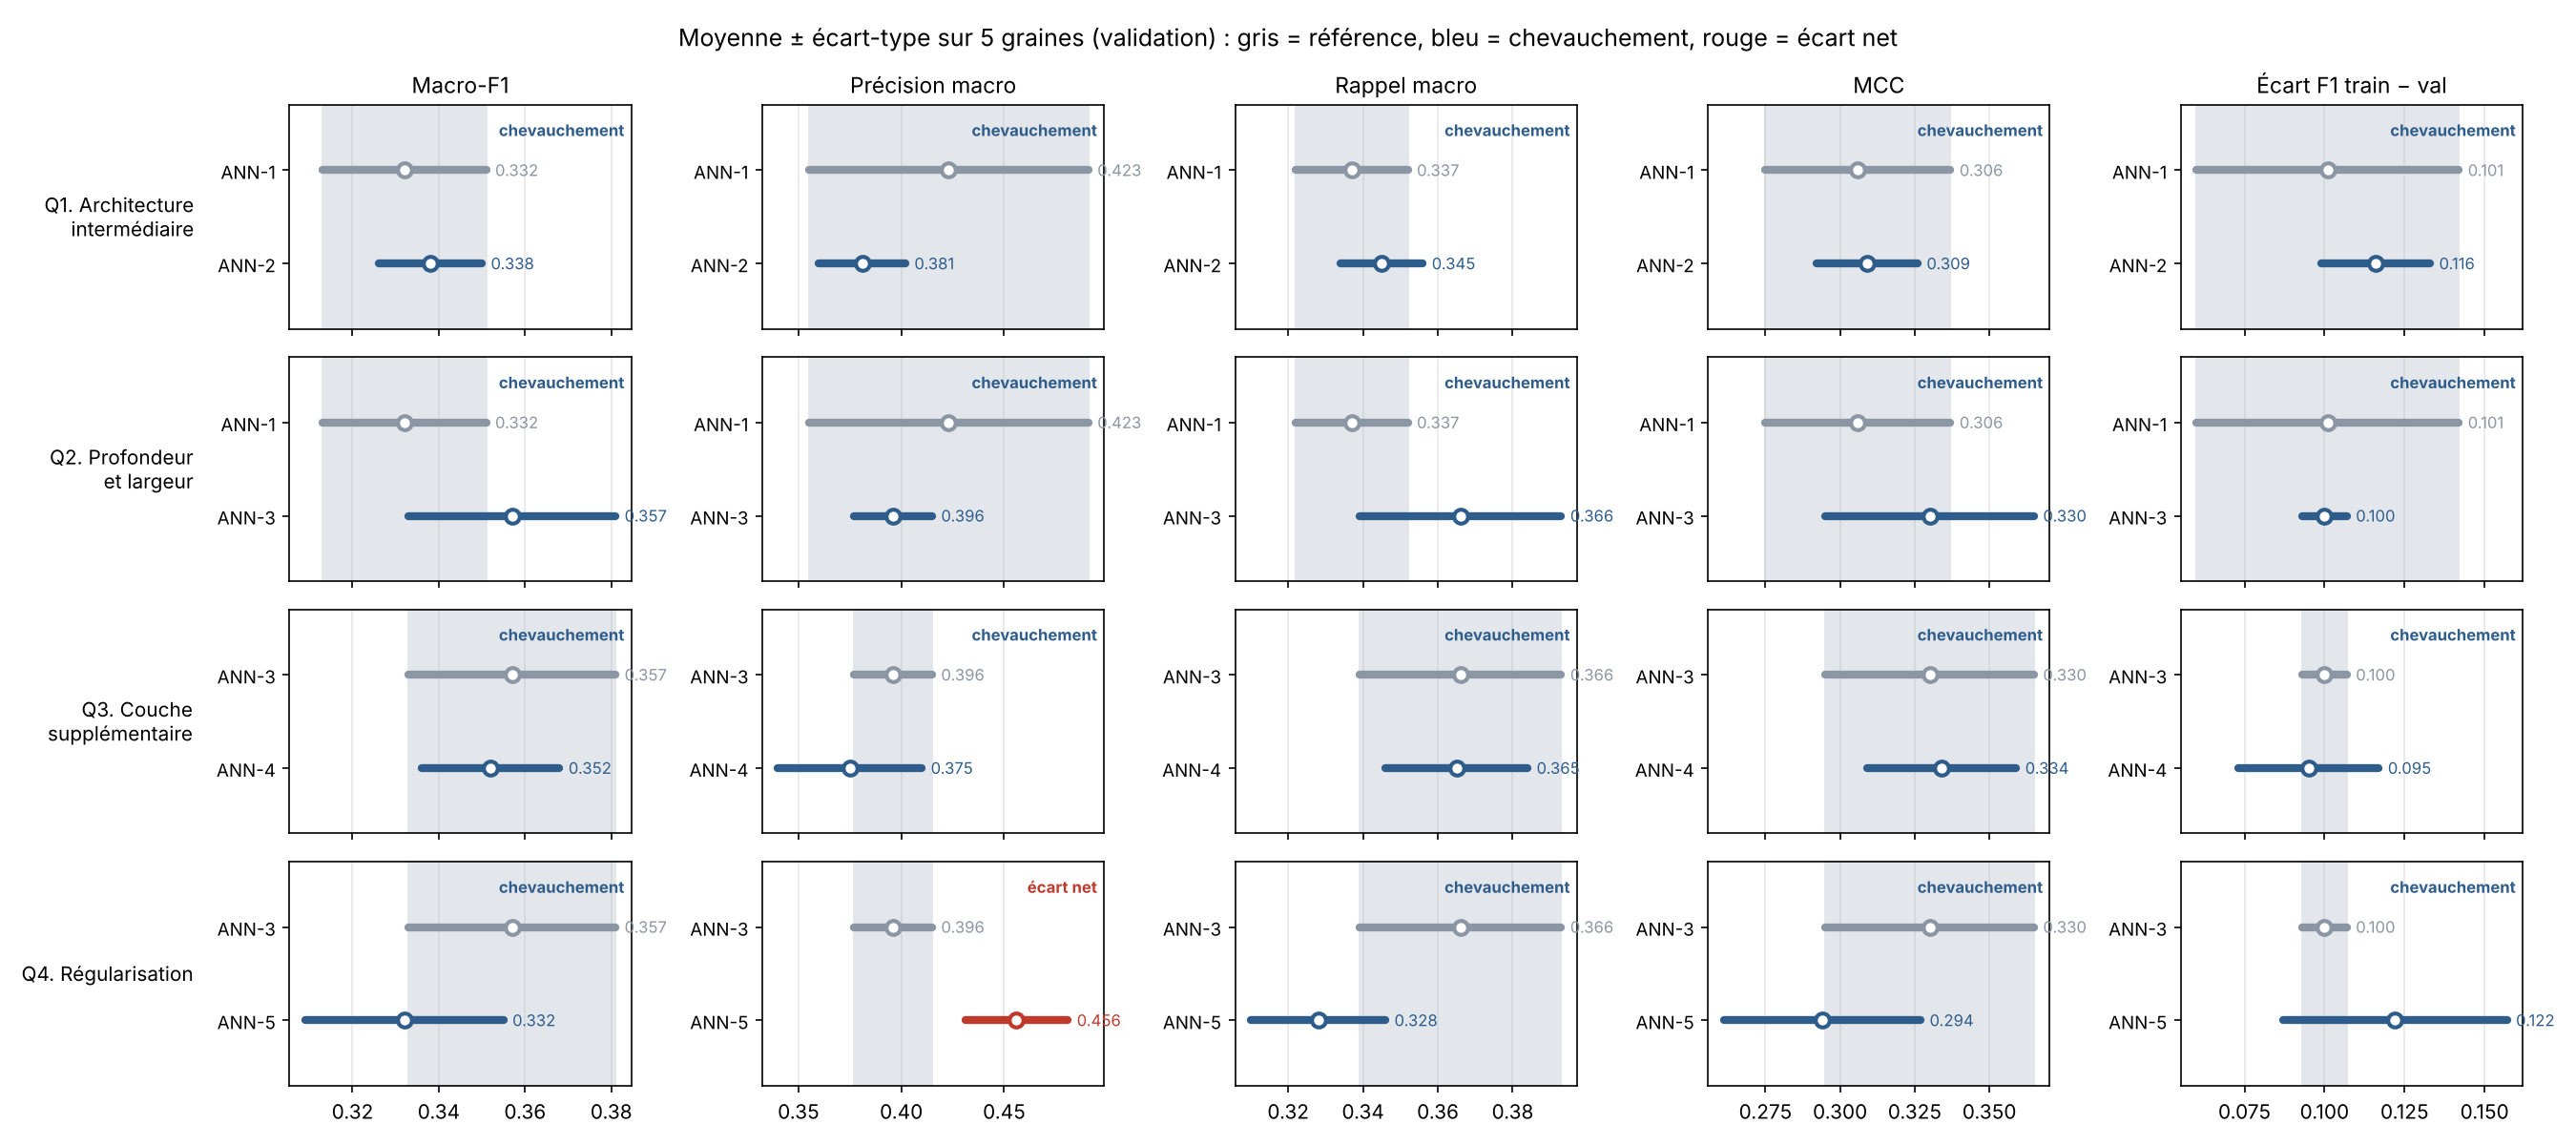


### Interprétation de l'expérience A : comparaison des architectures

Le jeu de données étant fortement déséquilibré, l'analyse s'appuie principalement sur le Macro-F1, complété par la précision macro, le rappel macro et le MCC.

**Lecture générale.** Au vu du déséquilibre des classe, l'accuracy ne permet pas de départager les modèles, ce qui confirme le choix du Macro-F1 comme critère principal.

**1. Une architecture intermédiaire améliore-t-elle les performances ? (ANN-1 → ANN-2)**
Passer d'une couche de 32 neurones à deux couches ne modifie presque pas les performances : le Macro-F1 passe de 0,332 ± 0,019 à 0,338 ± 0,012, le rappel macro de 0,337 à 0,345 et le MCC de 0,306 à 0,309. Ces gains restent inférieurs aux écarts-types. La précision macro baisse (0,423 → 0,381), mais la forte variabilité d'ANN-1 (± 0,068) rend cette baisse fragile. L'écart de F1 entre entraînement et validation augmente légèrement (0,101 → 0,116), sans dépasser la variabilité entre graines. L'architecture intermédiaire n'apporte donc pas d'amélioration nette ; elle converge en revanche plus vite (meilleure epoch : 39 contre 80).

**2. La profondeur et la largeur améliorent-elles les performances ? (ANN-1 → ANN-3)**

L'ANN-3 obtient le meilleur Macro-F1 moyen, 0,357 ± 0,024, contre 0,332 ± 0,019 pour l'ANN-1. Le rappel macro progresse (0,337 → 0,366) ainsi que le MCC (0,306 → 0,330), tandis que la précision macro baisse légèrement  : le réseau reconnaît un peu mieux les différentes classes, au prix de quelques fausses alertes supplémentaires. Avec la stabilité entre l'ecart de l'entrainement et de validation , nous pouvons-en plus des dire- deduire donc que l'augmentation de la capacité améliore la qualité moyenne de classification.

**3. Une couche cachée supplémentaire apporte-t-elle une valeur ajoutée ? (ANN-3 → ANN-4, et ANN-1 → ANN-4)**
Nos indicateurs de réferences varient tres peu : Macro-F1 de 0,352 ± 0,016 contre 0,357 ± 0,024, rappel macro équivalent (0,365 contre 0,366), MCC à peine supérieur (0,334 contre 0,330). La profondeur supplémentaire n'a pas de valeur ajoutée sur notre modele

**4. Quel est l'effet de la régularisation ? (ANN-3 → ANN-5)**
L'ANN-5 reprend l'architecture de l'ANN-3 en ajoutant la Batch Normalization et un Dropout de 0,2 . Elle obtient la précision macro la plus élevée (0,456 contre 0,396), mais le rappel macro le plus faible (0,328 contre 0,366), et son Macro-F1 recule (0,332 contre 0,357), tout comme son MCC (0,294 contre 0,330). Le modèle devient plus « prudent » : il annonce moins souvent les classes minoritaires, mais à plus juste titre quand il le fait. 

**Synthèse.** La profondeur et la largeur apportent au mieux un gain modeste, qui plafonne dès l'ANN-3 ; la régularisation testée dans l'ANN-5 n'améliore pas les résultats. L'ANN-3 offre le meilleur compromis entre performance (Macro-F1 le plus élevé) et complexité. Toutefois, les écarts entre architectures restent du même ordre que la variabilité due à l'initialisation, et tous les modèles plafonnent à un Macro-F1 d'environ 0,35 : la limite principale ne semble pas venir de l'architecture, mais de la difficulté à reconnaître les classes minoritaires et spectralement proches.


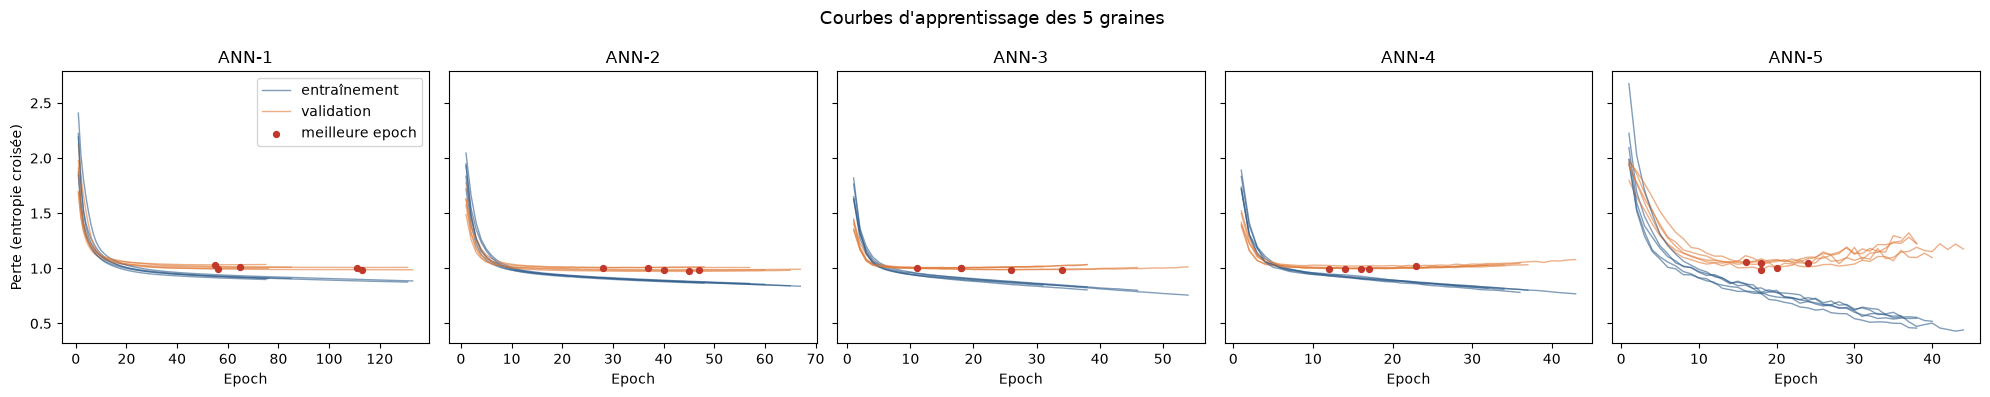

In [16]:
#  8. Graphique 1 : courbes d'apprentissage des 5 graines
# Chaque trait = un entraînement complet (pas de moyenne : les durées diffèrent à cause de
# l'arrêt anticipé). 

fig, axes = plt.subplots(1, len(ARCHITECTURES), figsize=(20, 4), sharey=True)
for ax, nom in zip(axes, ARCHITECTURES):
    for graine in GRAINES:
        h = historiques[(nom, graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]          # pour n'afficher la légende qu'une fois
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6,
                label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6,
                label="validation" if premiere else None)
        meilleure = int(np.argmin(h["val_loss"]))
        ax.scatter(meilleure + 1, h["val_loss"][meilleure], color="#c0392b", s=18, zorder=3,
                   label="meilleure epoch" if premiere else None)
    ax.set_title(nom)
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Perte (entropie croisée)")
axes[0].legend()
fig.suptitle("Courbes d'apprentissage des 5 graines ", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SORTIE, "courbes_apprentissage.png"), dpi=150)
plt.show()



#### interpretation

Chaque panneau présente, pour une architecture, l'évolution de la perte (entropie croisée) sur l'entraînement  et sur la validation pour les cinq graines.

**Comportement par architecture**
- **ANN-1** : les deux pertes diminuent rapidement puis se stabilisent ; la perte de validation reste stable autour de 1,0 sans remonter, et l'écart avec l'entraînement reste faible. Le modèle apprend lentement car ses meilleures epochs sont les plus tardives (entre 55 et 113 selon la graine).

- **ANN-2** : même profil, avec une convergence plus rapide (meilleures epochs entre 28 et 47). La perte d'entraînement continue de baisser alors que celle de validation reste stable : l'écart commence à se dessiner.
- **ANN-3** : la convergence est encore plus rapide, mais la meilleure epoch varie fortement selon la graine (entre 11 et 34 environ), ce qui montre que l'initialisation influence le moment optimal d'arrêt. En fin d'entraînement, la perte de validation remonte légèrement pendant que celle d'entraînement continue de baisser : un début de surapprentissage apparaît.
- **ANN-4** : les meilleures epochs sont précoces (entre 12 et 23) et la perte de validation remonte ensuite plus nettement (jusqu'à environ 1,07), tandis que la perte d'entraînement descend vers 0,77 : le surapprentissage commence plus tôt.
- **ANN-5** : c'est le cas le plus marqué. La perte d'entraînement chute jusqu'à environ 0,45, alors que la perte de validation remonte à partir d'une vingtaine d'epochs, les courbes sont aussi plus irrégulières. La Batch Normalization accélère l'apprentissage, mais le modèle surapprend rapidement, et le Dropout de 0,2 ne suffit pas à l'empêcher.

**synthese**

1. **Plus le réseau est profond, plus il apprend vite et plus le surapprentissage apparaît tôt.** 
2. **La graine influence l'epoch optimale.** Pour une même architecture, la meilleure epoch varie selon l'initialisation (de 11 à 34 pour l'ANN-3).
3. **La graine influence aussi la durée de l'apprentissage.** Avec certaines graines, la perte de validation continue de s'améliorer légèrement et le modèle poursuit son apprentissage ; avec d'autres, l'arrêt anticipé intervient plus tôt.


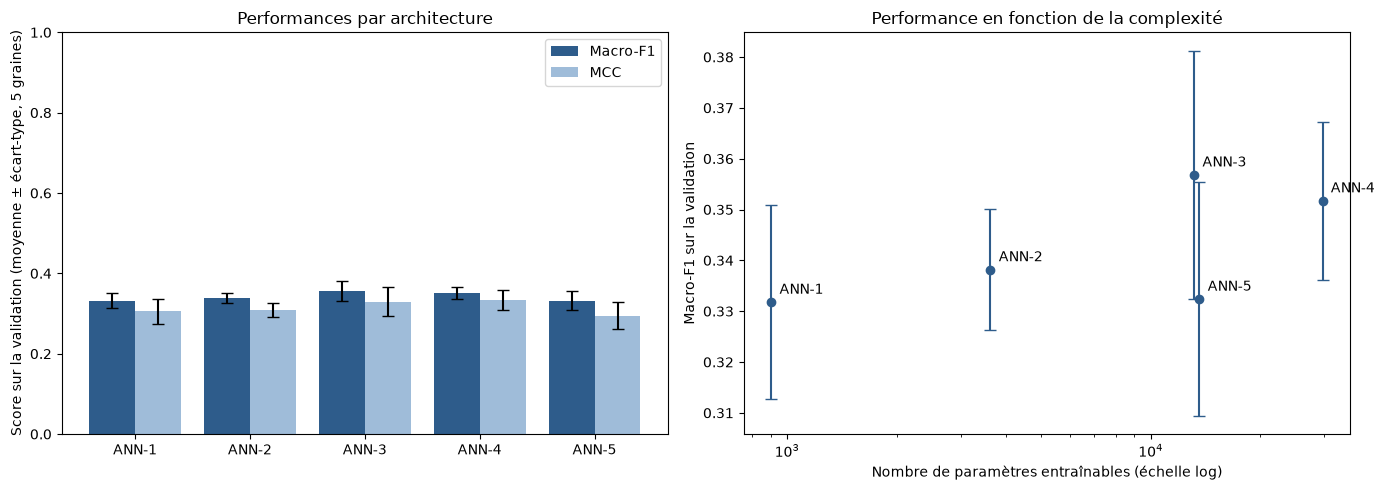

In [ ]:
# 9. Graphique 2 : comparaison des performances et lien avec la complexité
# Macro-F1 (critère principal) et MCC (score global robuste au déséquilibre).
#le kappa est contesté pour l'évaluation des cartes (Foody, 2020)

moy = resultats.groupby("modele").agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                                      mcc=("val_mcc", "mean"), mcc_sd=("val_mcc", "std"),
                                      parametres=("parametres", "first")).loc[list(ARCHITECTURES)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(moy))
axes[0].bar(x - 0.2, moy["f1"], 0.4, yerr=moy["f1_sd"], capsize=4, label="Macro-F1", color="#2e5c8b")
axes[0].bar(x + 0.2, moy["mcc"], 0.4, yerr=moy["mcc_sd"], capsize=4, label="MCC", color="#9fbcd9")
axes[0].set_xticks(x, moy.index)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Score sur la validation (moyenne ± écart-type, 5 graines)")
axes[0].set_title("Performances par architecture")
axes[0].legend(loc="upper right")

axes[1].errorbar(moy["parametres"], moy["f1"], yerr=moy["f1_sd"], fmt="o", capsize=4, color="#2e5c8b")
for nom, ligne in moy.iterrows():
    axes[1].annotate(nom, (ligne["parametres"], ligne["f1"]), xytext=(6, 6), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Nombre de paramètres entraînables (échelle log)")
axes[1].set_ylabel("Macro-F1 sur la validation")
axes[1].set_title("Performance en fonction de la complexité")
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SORTIE, "comparaison_architectures.png"), dpi=150)
plt.show()

#### Performance en fonction de la complexité
Le Macro-F1 tend à augmenter avec la complexité entre l'ANN-1 et l'ANN-3, puis plafonne : l'ANN-4, avec plus du double de paramètres, n'apporte pas de gain (0,352). Les barres d'erreur se chevauchent pour toutes les architectures. L'ANN-5 a presque le même nombre de paramètres que l'ANN-3; sa baisse de Macro-F1 (0,332) n'est donc pas liée à la complexité, mais à la régularisation ajoutée, avec laquelle le modèle surapprend plus vite.

#### Performances par architecture
Le Macro-F1 et le MCC évoluent dans le même sens : l'ANN-3 et l'ANN-4 obtiennent les valeurs les plus élevées, l'ANN-5 les plus faibles. Les écarts entre architectures restent du même ordre que les écarts-types. Les scores restent modestes (Macro-F1 inférieur à 0,36 pour toutes les architectures) : l'architecture n'est pas le principal facteur limitant.

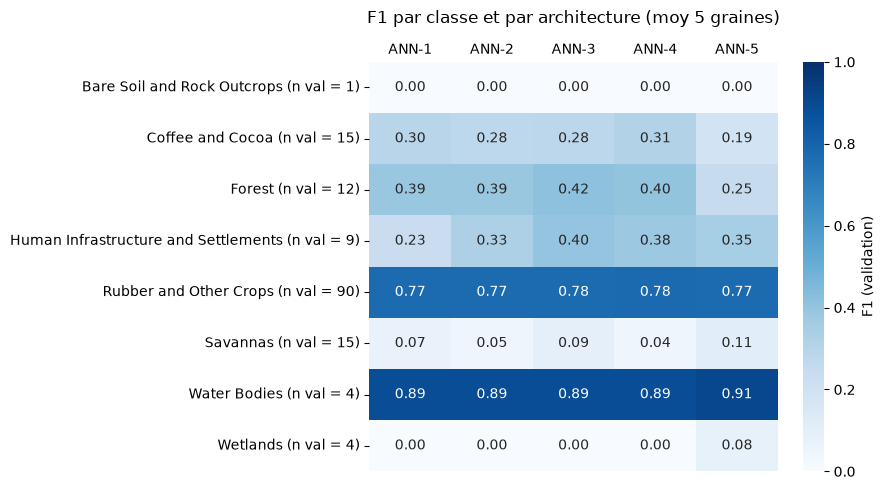

In [20]:
# 10. Graphique 3 : F1 par classe (validation, moyenne des 5 graines)
# Permet de voir si la profondeur aide surtout les classes minoritaires ou les classes proches.

f1_classes = pd.DataFrame({nom: np.mean([f1_par_classe[(nom, g)] for g in GRAINES], axis=0)
                           for nom in ARCHITECTURES}, index=NOMS_CLASSES)
effectifs_val = pd.Series(y_val).value_counts().reindex(range(N_CLASSES), fill_value=0).to_numpy()
f1_classes.index = [f"{c} (n val = {n})" for c, n in zip(NOMS_CLASSES, effectifs_val)]
f1_classes.to_csv(os.path.join(DOSSIER_SORTIE, "f1_par_classe.csv"))

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(f1_classes, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1 (validation)"})
ax.xaxis.tick_top()                     # noms des architectures au-dessus du graphique
ax.tick_params(axis="x", length=0)
ax.set_title("F1 par classe et par architecture (moy 5 graines)", pad=28)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SORTIE, "f1_par_classe.png"), dpi=150)
plt.show()
# certaines classes n'ont que 1 à 4 observations en validation
# leur F1 est très instable.


Les classes Bare Soil and Rock Outcrops et Wetlands ne sont reconnues par aucune architecture : leur F1 reste nul quelle que soit la complexité du réseau, à l’exception d’un 0,08 pour Wetlands avec l’ANN-5. Deux raisons l’expliquent. D’abord, elles disposent de très peu d’observations : 5 en entraînement et 1 en validation pour Bare Soil, 19 et 4 pour Wetlands. Le réseau a trop peu d’exemples pour les apprendre, et un seul point mal classé en validation suffit à annuler le F1. Ensuite, l’analyse exploratoire a montré que leurs signatures se confondent avec celles d’autres classes : Bare Soil est spectralement proche du bâti, et Wetlands, qui mélange eau, sol saturé et végétation, est la classe la plus dispersée.

Savannas est aussi presque jamais reconnue (F1 de 0,04 à 0,11), bien qu’elle compte 102 observations. Ici, l’effectif n’est donc pas en cause : sur le plan factoriel de l’ACP, la savane s’étale sur tout le nuage, comme Rubber, sans zone propre. Le réseau la confond avec la classe majoritaire.

Pour Forest et Coffee and Cocoa, le F1 varie peu de l’ANN-1 à l’ANN-4 (environ 0,40 et 0,30), puis recule avec l’ANN-5 (0,25 et 0,19), le modèle régularisé qui surapprend le plus. Ces deux classes occupent la même zone du plan factoriel (même vigueur végétale, même humidité) et ont des signatures très proches, ce qui limite leur séparation.

Deux classes sortent du lot, avec des F1 élevés et stables quelle que soit l’architecture : Water Bodies (0,89 à 0,91) et Rubber and Other Crops (0,77 à 0,78). Water Bodies a la signature spectrale la plus isolée  et elle est fortement regroupée autour du lac. Son F1 repose toutefois sur 4 observations de validation. 

La seule classe qui profite réellement de l’augmentation de la complexité est Human Infrastructure, dont le F1 passe de 0,23 (ANN-1) à 0,40 (ANN-3)

#### Architecture retenue 

 À l'issue de l'expérience A, c'est ANN-3 est le plus petit modèle qui atteint le plateau de performance :
- L'ANN-1 est une référence trop simple, moins performante.
- L'ANN-2 converge plus vite mais son architecture intermédiaire n'apporte pas d'amélioration nette.
- l'ANN-4, avec plus du double de paramètres, n'apporte pas de gain. 
- L'ANN-5 surapprend rapidement.

### EXPÉRIENCE B : comparaison des Optimiseurs
#### Objectif :  comparer cinq optimiseurs pour entraîner le même réseau, et voir lequel donne le modèle qui généralise le mieux. 

#### Principe directeur : une seule architecture, la même fonction de perte, les mêmes partitions et le même budget maximal d’époques. La même pour les cinq optimiseurs.
#### Les critères de comparaison seront : 
   - la performance sur l’ensemble de validation ; 
   - le nombre d’époques nécessaires à la convergence ; 
   - la stabilité des courbes de perte ; 
   - le temps d’entraînement ; 
   - l’écart entre les performances d’entraînement et de validation. 


#### Paramètres de l'expérience B

In [25]:

# On réutilise ce qui a été défini pour l'expérience A : X_train, X_val, y_train, y_val, ARCHITECTURES,
# construire_modele, calculer_metriques, GRAINES, EPOCHS_MAX, PATIENCE, TAILLE_LOT.

DOSSIER_SORTIE_B = os.path.join("resultats", "experience_B")
ARCHI_B = "ANN-3"                                 # architecture retenue 

# Vérification : les partitions utilisées sont bien celles enregistrées pendant l'expérience A
partitions_A = pd.read_csv(os.path.join(DOSSIER_SORTIE, "partitions.csv"))
assert (partitions_A["ensemble"].to_numpy() == partitions["ensemble"].to_numpy()).all(), "Partitions différentes !"
partitions.to_csv(os.path.join(DOSSIER_SORTIE_B, "partitions.csv"), index=False)   # copie dans le dossier B

print(f"Architecture : {ARCHI_B} {ARCHITECTURES[ARCHI_B]}")
print(f"Train : {len(y_train)} | Validation : {len(y_val)} | Graines : {GRAINES}")
print(f"Budget : {EPOCHS_MAX} epochs max, patience {PATIENCE}, lots de {TAILLE_LOT}")

Architecture : ANN-3 [128, 64, 32]
Train : 700 | Validation : 150 | Graines : [0, 1, 2, 3, 4]
Budget : 200 epochs max, patience 20, lots de 32


In [26]:
# B.1 Fonctions de l'expérience B

def creer_optimiseur(nom, params):
    """Crée un nouvel optimiseur Keras. Les paramètres non précisés gardent leur valeur par défaut."""
    if nom in ("SGD", "SGD + Momentum"):
        return keras.optimizers.SGD(learning_rate=params["lr"], momentum=params.get("momentum", 0.0))
    if nom == "Adam":
        return keras.optimizers.Adam(learning_rate=params["lr"])          # beta_1, beta_2, epsilon par défaut
    if nom == "RMSprop":
        return keras.optimizers.RMSprop(learning_rate=params["lr"])       # rho, epsilon par défaut
    if nom == "AdamW":
        return keras.optimizers.AdamW(learning_rate=params["lr"], weight_decay=params["weight_decay"])
    raise ValueError(f"Optimiseur inconnu : {nom}")


def etiquette(params):
    """Nom lisible d'une configuration, par exemple 'lr=0.001, wd=0.004'."""
    noms = {"lr": "lr", "momentum": "momentum", "weight_decay": "wd"}
    return ", ".join(f"{noms[k]}={v:g}" for k, v in params.items())


def instabilite(pertes_val):
    """Mesure des oscillations de la perte de validation.
    On retire la tendance (mediane mobile sur 5 epochs) et on garde l'écart moyen à cette tendance :
    plus la valeur est grande, plus la courbe oscille."""
    p = pd.Series(pertes_val).dropna()
    tendance = p.rolling(5, center=True, min_periods=1).median()
    return float((p - tendance).abs().mean())


def entrainer_config(optimiseur, params, graine):
    """Entraîne l'ANN-3 avec un optimiseur et une graine, et renvoie les indicateurs."""
    keras.utils.set_random_seed(graine)        # même graine -> mêmes poids de départ pour tous les optimiseurs
    modele = construire_modele(ARCHI_B, ARCHITECTURES[ARCHI_B])     # même construction que dans l'expérience A
    modele.compile(optimizer=creer_optimiseur(optimiseur, params),  # seul l'optimiseur change
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])

    temps_epochs = []                                  # temps écoulé a la fin de chaque epoque
    rappels = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE,
                                             restore_best_weights=True),
               keras.callbacks.TerminateOnNaN(),      # arrête l'entraînement si y'a divergence 
               keras.callbacks.LambdaCallback(        # chronomètre : note le temps à la fin de chaque epoch
                   on_epoch_end=lambda epoch, logs: temps_epochs.append(time.perf_counter() - debut))]
    debut = time.perf_counter()
    hist = modele.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=EPOCHS_MAX, batch_size=TAILLE_LOT, callbacks=rappels, verbose=0)
    duree = time.perf_counter() - debut

    pertes_val = np.array(hist.history["val_loss"], dtype=float)
    diverge = bool(np.isnan(pertes_val).any() or np.isnan(hist.history["loss"]).any())
    pred_train = modele.predict(X_train, verbose=0).argmax(axis=1)
    pred_val = modele.predict(X_val, verbose=0).argmax(axis=1)
    m_train = calculer_metriques(y_train, pred_train)
    m_val = calculer_metriques(y_val, pred_val)

    ligne = {
        "optimiseur": optimiseur, "config": etiquette(params), "graine": graine, **params,
        "epochs_effectuees": len(pertes_val),
        # Convergence : epoch où la perte de validation est minimale 
        "meilleure_epoch": int(np.nanargmin(pertes_val)) + 1 if not np.isnan(pertes_val).all() else np.nan,
        "temps_s": duree,
        "perte_val": float(np.nanmin(pertes_val)) if not np.isnan(pertes_val).all() else np.nan,
        "instabilite_val": instabilite(pertes_val),
        "diverge": diverge,
        **{f"val_{k}": v for k, v in m_val.items()},
        "train_f1_macro": m_train["f1_macro"],
        "ecart_f1_train_val": m_train["f1_macro"] - m_val["f1_macro"],   # généralisation, plus il est faible plus le modele generalise bien
    }
    f1_classes = f1_score(y_val, pred_val, average=None, labels=range(N_CLASSES), zero_division=0)
    historique = dict(hist.history)
    historique["temps_cumule"] = temps_epochs          # ajouté aux courbes pour le graphique en fonction du temps
    return ligne, historique, f1_classes


# Stockage de tous les entraînements
reglage = []            # une ligne par (optimiseur, configuration, graine)
historiques_B = {}      # courbes d'apprentissage
f1_par_classe_B = {}    # F1 de chaque classe sur la validation
CONFIGS = {}            # (optimiseur, configuration) -> paramètres


def lancer(optimiseur, params):
    """Entraîne une configuration avec les 5 graines (sauf si elle a déjà été entraînée)."""
    config = etiquette(params)
    if (optimiseur, config) in CONFIGS:
        return
    CONFIGS[(optimiseur, config)] = params
    for graine in GRAINES:
        ligne, histo, f1c = entrainer_config(optimiseur, params, graine)
        reglage.append(ligne)
        historiques_B[(optimiseur, config, graine)] = histo
        f1_par_classe_B[(optimiseur, config, graine)] = f1c
        print(f"{optimiseur:15s} | {config:22s} | graine {graine} | {ligne['epochs_effectuees']:3d} epochs | "
              f"Macro-F1 val = {ligne['val_f1_macro']:.3f} | {ligne['temps_s']:.1f} s"
              + (" | DIVERGENCE" if ligne["diverge"] else ""))


def meilleure_config(optimiseur):
    """Configuration de meilleur Macro-F1 moyen (5 graines) sur la validation."""
    d = pd.DataFrame(reglage)
    return d[d["optimiseur"] == optimiseur].groupby("config")["val_f1_macro"].mean().idxmax()

#####  Réglage du taux d'apprentissage (SGD, Adam, RMSprop, AdamW)

Ici nous testons 3 taux d’apprentissage pour chacun des quatre optimiseurs SGD, Adam, RMSprop et AdamW, chacun avec les 5 graines et on retient les meilleurs. puis nous passons au choix du second parametre (AdamW et SGD + Momentum)

In [27]:
#l’effet du taux d’apprentissage dépend de son ordre de grandeur plutôt que de sa valeur exacte 

WD_DEFAUT = 0.004                                     
GRILLES_LR = {
    "SGD":     [0.001, 0.01, 0.1],                    
    "Adam":    [0.0001, 0.001, 0.01],                 
    "RMSprop": [0.0001, 0.001, 0.01],                
    "AdamW":   [0.0001, 0.001, 0.01],                 
}

for optimiseur, valeurs in GRILLES_LR.items():
    for lr in valeurs:
        params = {"lr": lr, "weight_decay": WD_DEFAUT} if optimiseur == "AdamW" else {"lr": lr}
        lancer(optimiseur, params)

SGD             | lr=0.001               | graine 0 | 200 epochs | Macro-F1 val = 0.224 | 149.8 s
SGD             | lr=0.001               | graine 1 | 200 epochs | Macro-F1 val = 0.232 | 72.0 s
SGD             | lr=0.001               | graine 2 | 200 epochs | Macro-F1 val = 0.207 | 61.9 s
SGD             | lr=0.001               | graine 3 | 200 epochs | Macro-F1 val = 0.262 | 57.0 s
SGD             | lr=0.001               | graine 4 | 200 epochs | Macro-F1 val = 0.249 | 63.7 s
SGD             | lr=0.01                | graine 0 | 200 epochs | Macro-F1 val = 0.421 | 76.1 s
SGD             | lr=0.01                | graine 1 | 189 epochs | Macro-F1 val = 0.346 | 64.8 s
SGD             | lr=0.01                | graine 2 | 196 epochs | Macro-F1 val = 0.332 | 69.8 s
SGD             | lr=0.01                | graine 3 | 182 epochs | Macro-F1 val = 0.423 | 72.7 s
SGD             | lr=0.01                | graine 4 | 196 epochs | Macro-F1 val = 0.357 | 81.4 s
SGD             | lr=0.1     

In [29]:
# Réglage du second paramètre : momentum (SGD + Momentum) et weight_decay (AdamW)

# SGD + Momentum : on part du taux d'apprentissage retenu pour SGD, seul le momentum change
lr_sgd = CONFIGS[("SGD", meilleure_config("SGD"))]["lr"]
print(f"Taux retenu pour SGD : {lr_sgd:g}")
for mu in [0.5, 0.9, 0.99]:
    lancer("SGD + Momentum", {"lr": lr_sgd, "momentum": mu})

# AdamW : on part du taux d'apprentissage retenu, seul le weight_decay change
lr_adamw = CONFIGS[("AdamW", meilleure_config("AdamW"))]["lr"]
print(f"Taux retenu pour AdamW : {lr_adamw:g}")
for wd in [0.0004, 0.004, 0.04]:
    lancer("AdamW", {"lr": lr_adamw, "weight_decay": wd})    # la valeur par défaut déjà entraînée est sautée

reglage_df = pd.DataFrame(reglage)
reglage_df.to_csv(os.path.join(DOSSIER_SORTIE_B, "reglage_detaille.csv"), index=False)

Taux retenu pour SGD : 0.01
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 0 | 105 epochs | Macro-F1 val = 0.346 | 37.8 s
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 1 | 111 epochs | Macro-F1 val = 0.374 | 37.3 s
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 2 | 107 epochs | Macro-F1 val = 0.329 | 44.2 s
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 3 |  94 epochs | Macro-F1 val = 0.425 | 35.8 s
SGD + Momentum  | lr=0.01, momentum=0.5  | graine 4 | 113 epochs | Macro-F1 val = 0.332 | 44.6 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 0 |  47 epochs | Macro-F1 val = 0.338 | 20.4 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 1 |  38 epochs | Macro-F1 val = 0.367 | 17.3 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 2 |  36 epochs | Macro-F1 val = 0.369 | 16.9 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 3 |  47 epochs | Macro-F1 val = 0.362 | 17.2 s
SGD + Momentum  | lr=0.01, momentum=0.9  | graine 4 |  29 epochs | Macro-F1 val = 0.334 | 12.8 s
SG

In [34]:
# Tableau du réglage : moyenne ± écart-type sur les 5 graines, pour chaque configuration testée

OPTIMISEURS = ["SGD", "SGD + Momentum", "Adam", "RMSprop", "AdamW"]
RETENUES = {opt: meilleure_config(opt) for opt in OPTIMISEURS}      # configuration retenue par optimiseur

tab_reglage = (reglage_df.groupby(["optimiseur", "config"], sort=False)
               .agg(f1_moy=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                    meilleure_epoch=("meilleure_epoch", "mean"), divergences=("diverge", "sum"))
               .reset_index())
tab_reglage["Macro-F1 val"] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(tab_reglage["f1_moy"], tab_reglage["f1_sd"])]
tab_reglage["retenue"] = [("oui" if RETENUES[o] == c else "") for o, c in zip(tab_reglage["optimiseur"], tab_reglage["config"])]
tab_reglage = tab_reglage[["optimiseur", "config", "Macro-F1 val", "meilleure_epoch", "divergences", "retenue"]]
tab_reglage.to_csv(os.path.join(DOSSIER_SORTIE_B, "reglage_recapitulatif.csv"), index=False)

#### Macro-F1 selon la valeur du paramètre réglé (moyenne ± écart-type, 5 graines)

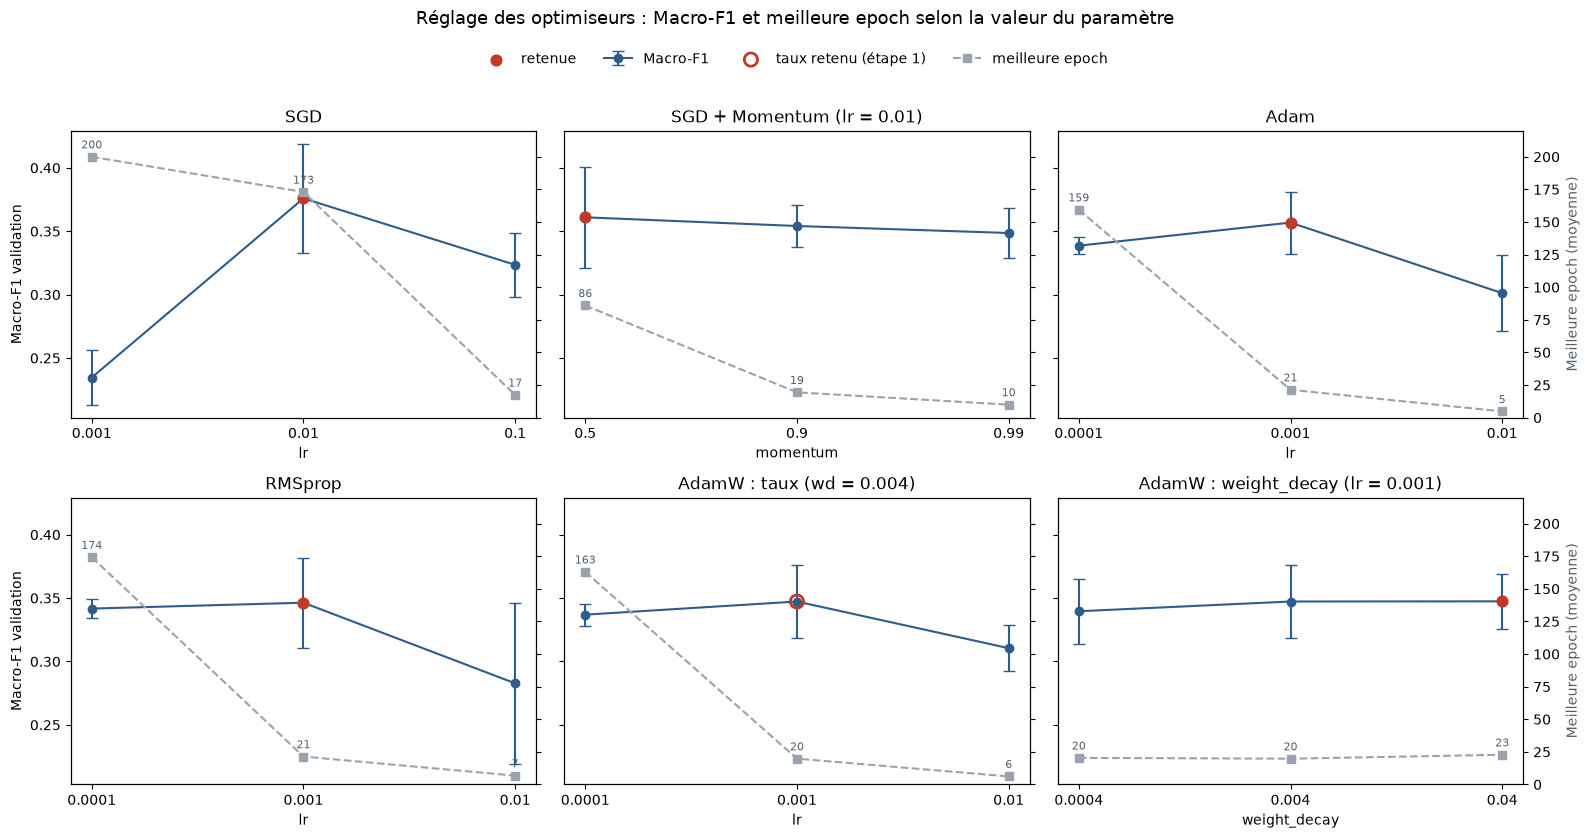

In [35]:
 
# Le point rouge indique la configuration retenue.

def tracer_reglage(ax, optimiseur, parametre, filtre=None, titre=None):
    d = reglage_df[reglage_df["optimiseur"] == optimiseur]
    if filtre is not None:
        d = d[filtre(d)]
    g = d.groupby(parametre).agg(f1=("val_f1_macro", "mean"), f1_sd=("val_f1_macro", "std"),
                                 ep=("meilleure_epoch", "mean")).sort_index()
    x = np.arange(len(g))                                   # positions régulières, valeurs en étiquettes

    # Axe de gauche : Macro-F1 moyen ± écart-type
    ax.errorbar(x, g["f1"], yerr=g["f1_sd"], fmt="o-", capsize=4, color="#2e5c8b", label="Macro-F1")
    if RETENUES[optimiseur] in d["config"].values:          # la configuration retenue est-elle dans ce panneau ?
        i = list(g.index).index(CONFIGS[(optimiseur, RETENUES[optimiseur])][parametre])
        ax.scatter(i, g["f1"].iloc[i], color="#c0392b", s=60, zorder=3, label="retenue")

    # Axe de droite : meilleure epoch moyenne (convergence)
    ax2 = ax.twinx()
    ax2.plot(x, g["ep"], "s--", color="#9aa3ad", label="meilleure epoch")
    for xi, e in zip(x, g["ep"]):
        ax2.annotate(f"{e:.0f}", (xi, e), xytext=(0, 6), textcoords="offset points",
                     ha="center", fontsize=8, color="#55606b")
    ax2.set_ylim(0, EPOCHS_MAX + 20)                         # même échelle pour tous les panneaux

    ax.set_xticks(x, [f"{v:g}" for v in g.index])
    ax.set_xlabel(parametre)
    ax.set_title(titre or optimiseur)
    return g, ax2

fig, axes = plt.subplots(2, 3, figsize=(16, 8.5), sharey=True)
_, ax2_sgd = tracer_reglage(axes[0, 0], "SGD", "lr")
_, ax2_mom = tracer_reglage(axes[0, 1], "SGD + Momentum", "momentum", titre=f"SGD + Momentum (lr = {lr_sgd:g})")
_, ax2_adam = tracer_reglage(axes[0, 2], "Adam", "lr")
_, ax2_rms = tracer_reglage(axes[1, 0], "RMSprop", "lr")
g_aw, ax2_aw = tracer_reglage(axes[1, 1], "AdamW", "lr", filtre=lambda d: d["weight_decay"] == WD_DEFAUT,
                              titre=f"AdamW : taux (wd = {WD_DEFAUT:g})")
_, ax2_wd = tracer_reglage(axes[1, 2], "AdamW", "weight_decay", filtre=lambda d: d["lr"] == lr_adamw,
                           titre=f"AdamW : weight_decay (lr = {lr_adamw:g})")

# AdamW : cercle rouge sur le taux retenu à l'étape 1 (avant le réglage du weight_decay)
i = list(g_aw.index).index(lr_adamw)
axes[1, 1].scatter(i, g_aw["f1"].iloc[i], s=90, facecolors="none", edgecolors="#c0392b", linewidths=2,
                   zorder=4, label="taux retenu (étape 1)")

for ax in axes[:, 0]:
    ax.set_ylabel("Macro-F1 validation")
for ax2 in [ax2_sgd, ax2_mom, ax2_rms, ax2_aw]:
    ax2.tick_params(labelright=False)                        # graduations de droite seulement sur la dernière colonne
for ax2 in [ax2_adam, ax2_wd]:
    ax2.set_ylabel("Meilleure epoch (moyenne)", color="#55606b")

# Légende commune placée sous le titre 
h1, l1 = axes[0, 0].get_legend_handles_labels()              # Macro-F1, retenue
h2, l2 = axes[1, 1].get_legend_handles_labels()              # taux retenu (étape 1)
h3, l3 = ax2_sgd.get_legend_handles_labels()                 # meilleure epoch
poignees = dict(zip(l1 + l2 + l3, h1 + h2 + h3))             # dictionnaire : évite les doublons
fig.legend(poignees.values(), poignees.keys(), loc="upper center", ncol=4,
           bbox_to_anchor=(0.5, 0.945), frameon=False, fontsize=10)

fig.suptitle("Réglage des optimiseurs : Macro-F1 et meilleure epoch selon la valeur du paramètre", fontsize=13)
plt.tight_layout(rect=[0, 0, 1, 0.92])                       # laisse de la place en haut pour la légende
plt.savefig(os.path.join(DOSSIER_SORTIE_B, "reglage_parametres.png"), dpi=150)
plt.show()

Le taux d’apprentissage est le paramètre qui influence le plus le Macro-F1, en particulier pour SGD (de 0,235 à 0,376). Pour Adam, RMSprop et AdamW, le taux de 0,01 donne les scores les plus faibles par contre le taux de 0.001 permet d'avoir un macro-F1 elévé. L’ajout du momentum à SGD n’améliore pas le Macro-F1 en validation mais permet d'accélèrer surtout la convergence (meilleure epoch de 173 sans momentum à 10 avec un momentum de 0,99). De même, le weight_decay d’AdamW fait peu varier le Macro-F1 (de 0,340 à 0,347).

#### Comparaison des optimiseurs retenus


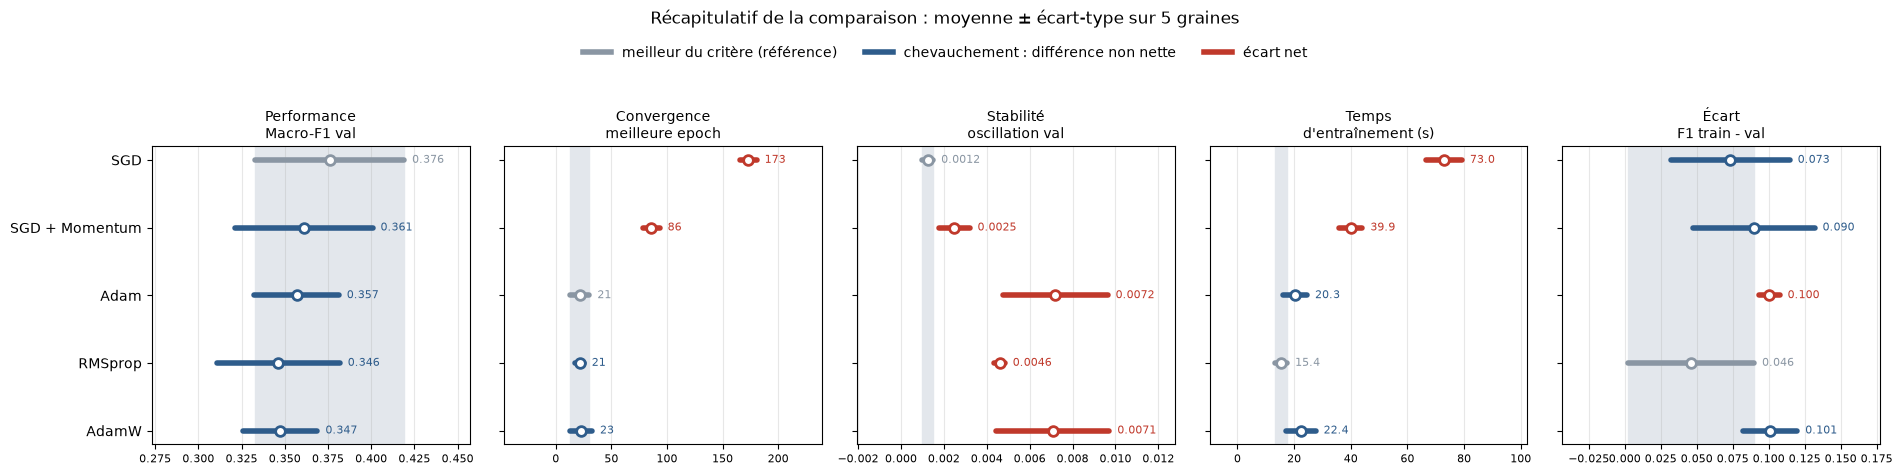

In [41]:
# Tableau récapitulatif des optimiseurs retenus (validation, moyenne ± écart-type sur 5 graines)


garder = [(o, RETENUES[o]) for o in OPTIMISEURS]
resultats_B = reglage_df[[(o, c) in garder for o, c in zip(reglage_df["optimiseur"], reglage_df["config"])]].copy()
resultats_B.to_csv(os.path.join(DOSSIER_SORTIE_B, "resultats_detailles.csv"), index=False)

colonnes_B = ["val_f1_macro", "val_mcc", "val_accuracy", "val_precision_macro", "val_recall_macro",
              "val_f1_pondere", "ecart_f1_train_val", "meilleure_epoch", "epochs_effectuees",
              "instabilite_val", "temps_s"]
recap_B = resultats_B.groupby("optimiseur")[colonnes_B].agg(["mean", "std"]).loc[OPTIMISEURS]

tableau_B = pd.DataFrame(index=recap_B.index)
tableau_B["Configuration"] = [RETENUES[o] for o in OPTIMISEURS]
for c in colonnes_B:
    dec = 0 if c in ("meilleure_epoch", "epochs_effectuees") else (1 if c == "temps_s" else 3)
    tableau_B[c] = [f"{m:.{dec}f} ± {s:.{dec}f}" for m, s in zip(recap_B[(c, "mean")], recap_B[(c, "std")])]
tableau_B.to_csv(os.path.join(DOSSIER_SORTIE_B, "recapitulatif_optimiseurs.csv"))


criteres_chev = [  # (colonne, titre, format, sens : True = plus grand est meilleur)
    ("val_f1_macro", "Performance\nMacro-F1 val", ".3f", True),
    ("meilleure_epoch", "Convergence\nmeilleure epoch", ".0f", False),
    ("instabilite_val", "Stabilité\noscillation val", ".4f", False),
    ("temps_s", "Temps\nd'entraînement (s)", ".1f", False),
    ("ecart_f1_train_val", "Écart\nF1 train - val", ".3f", False),
]
stats_chev = resultats_B.groupby("optimiseur")[[c for c, _, _, _ in criteres_chev]].agg(["mean", "std"]).loc[OPTIMISEURS]

fig, axes = plt.subplots(1, len(criteres_chev), figsize=(19, 4.8), sharey=True)
y = np.arange(len(OPTIMISEURS))[::-1]                        # premier optimiseur en haut
for ax, (col, titre, fmt, plus_grand_meilleur) in zip(axes, criteres_chev):
    m, s = stats_chev[(col, "mean")], stats_chev[(col, "std")]
    meilleur = m.idxmax() if plus_grand_meilleur else m.idxmin()
    bas_ref, haut_ref = m[meilleur] - s[meilleur], m[meilleur] + s[meilleur]
    ax.axvspan(bas_ref, haut_ref, color="#e3e7ec")             # bande de référence
    for yi, opt in zip(y, OPTIMISEURS):
        bas, haut = m[opt] - s[opt], m[opt] + s[opt]
        if opt == meilleur:
            c = "#8a96a3"
        else:
            chevauche = bas <= haut_ref and haut >= bas_ref
            c = "#2e5c8b" if chevauche else "#c0392b"
        ax.plot([bas, haut], [yi, yi], color=c, lw=4, solid_capstyle="round")
        ax.plot(m[opt], yi, "o", color="white", mec=c, mew=2, ms=7)
        ax.text(haut, yi, f"  {m[opt]:{fmt}}", va="center", fontsize=8, color=c)
    ax.set_title(titre, fontsize=10)
    ax.margins(x=0.35)                                         # place pour les valeurs à droite
    ax.grid(axis="x", alpha=0.3)
    ax.tick_params(axis="x", labelsize=8)
axes[0].set_yticks(y, OPTIMISEURS)

legende = [Line2D([0], [0], color="#8a96a3", lw=4, label="meilleur du critère (référence)"),
           Line2D([0], [0], color="#2e5c8b", lw=4, label="chevauchement : différence non nette"),
           Line2D([0], [0], color="#c0392b", lw=4, label="écart net")]
fig.legend(handles=legende, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.93), frameon=False, fontsize=10)
fig.suptitle("Récapitulatif de la comparaison : moyenne ± écart-type sur 5 graines", fontsize=12)
plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.savefig(os.path.join(DOSSIER_SORTIE_B, "recapitulatif_chevauchement.png"), dpi=150)
plt.show()



Au regard des critères de comparaison, aucun optimiseur n’arrive en tête sur tous les critères, compte tenu du sens de lecture de chacun (plus haut est meilleur pour le Macro-F1, plus bas est meilleur pour les autres).

Résumé par optimiseur

SGD : il a le meilleur Macro-F1 moyen (0,376), mais avec l’écart-type le plus grand (± 0,043), et tous les autres optimiseurs le chevauchent. En revanche, il converge nettement le plus lentement (meilleure epoch 173, proche du budget de 200) et c’est le plus long à entraîner (73 s). Son écart entraînement / validation (0,073) chevauche celui du meilleur.

SGD + Momentum : son Macro-F1 (0,361) chevauche celui de SGD. Le momentum divise par deux la convergence (86 epochs) et le temps (39,9 s) par rapport à SGD, mais il reste nettement plus lent que les optimiseurs adaptatifs. Ses courbes sont nettement moins stables que celles de SGD. Son écart entraînement / validation (0,090) chevauche celui du meilleur.

Adam : son Macro-F1 (0,357) chevauche celui des autres. Il converge le plus vite (21 epochs), et son temps (20,3 s) chevauche celui de RMSprop. Ses courbes sont nettement les moins stables (0,0072). Son écart entraînement / validation (0,100) est le seul « écart net » face à RMSprop, mais il est très régulier d’une graine à l’autre (± 0,007).

RMSprop : il a le Macro-F1 moyen le plus bas (0,346), sans écart net avec les autres. Il converge aussi vite qu’Adam (21 epochs) et c’est le plus rapide en temps (15,4 s). Sa stabilité est intermédiaire (0,0046), nettement moins bonne que celle de SGD. Il a le plus petit écart entraînement / validation (0,046), mais avec un écart-type presque aussi grand que la valeur (± 0,044) : ce résultat est donc peu fiable.

AdamW : il se comporte presque comme Adam. Son Macro-F1 (0,347), sa convergence (23 epochs) et son temps (22,4 s) chevauchent tous la référence. Ses courbes sont aussi instables que celles d’Adam (0,0071). Son écart entraînement / validation (0,101) est presque identique à celui d’Adam : le weight_decay retenu n’a pas réduit cet écart.

En résumé : sur le critère principal, le Macro-F1 en validation, aucun optimiseur ne se distingue nettement. Les écarts nets portent sur la vitesse de convergence, le temps d’entraînement et la stabilité des courbes, qui ne doivent servir qu’à départager. analysons les courbes d'apprentissage

 #### courbes d'apprentissage des 5 graines pour chaque optimiseur retenu

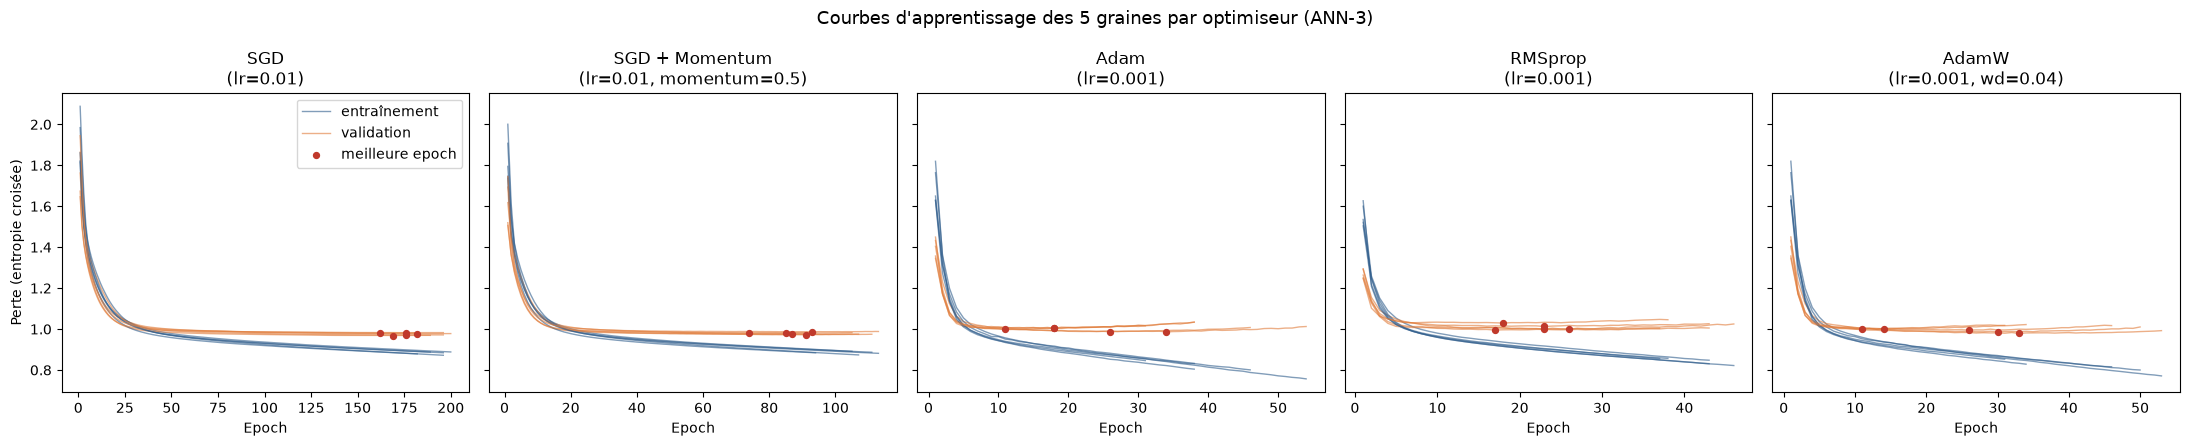

In [ ]:


fig, axes = plt.subplots(1, len(OPTIMISEURS), figsize=(22, 4.5), sharey=True)
for ax, opt in zip(axes, OPTIMISEURS):
    for graine in GRAINES:
        h = historiques_B[(opt, RETENUES[opt], graine)]
        epochs = np.arange(1, len(h["loss"]) + 1)
        premiere = graine == GRAINES[0]                 # légende affichée une seule fois
        ax.plot(epochs, h["loss"], color="#2e5c8b", lw=1, alpha=0.6,
                label="entraînement" if premiere else None)
        ax.plot(epochs, h["val_loss"], color="#e07b39", lw=1, alpha=0.6,
                label="validation" if premiere else None)
        meilleure = int(np.nanargmin(h["val_loss"]))
        ax.scatter(meilleure + 1, h["val_loss"][meilleure], color="#c0392b", s=18, zorder=3,
                   label="meilleure epoch" if premiere else None)
    ax.set_title(f"{opt}\n({RETENUES[opt]})")
    ax.set_xlabel("Epoch")
axes[0].set_ylabel("Perte (entropie croisée)")
axes[0].legend()
fig.suptitle("Courbes d'apprentissage des 5 graines par optimiseur (ANN-3)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SORTIE_B, "courbes_apprentissage.png"), dpi=150)
plt.show()

Avec SGD et SGD + Momentum, les courbes sont les plus régulières : les pertes d’entraînement et de validation diminuent ensemble et restent proches, et la perte de validation ne remonte pas. SGD + Momentum converge environ deux fois plus vite que SGD (meilleure epoch d’environ 86 contre 173). Avec Adam, RMSprop et AdamW, la convergence est beaucoup plus rapide (une vingtaine d’epochs), mais la perte d’entraînement continue de baisser alors que la perte de validation se stabilise puis remonte légèrement : un début de surapprentissage apparaît, interrompu par l’arrêt anticipé. Comme dans l’expérience A, l’initialisation influence le moment optimal d’arrêt, surtout pour les optimiseurs adaptatifs (meilleure epoch d’environ 11 à 34 selon la graine pour Adam), alors qu’elle varie peu pour SGD.


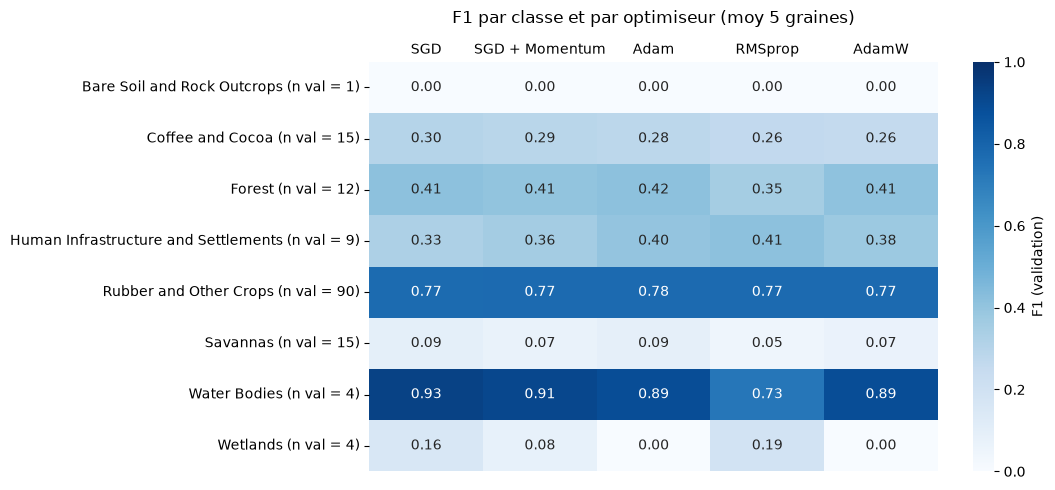

In [46]:
# B.14 Graphique 8 : F1 par classe et par optimiseur (validation, moyenne des 5 graines)
# Détail de la performance en validation, dans le même format que pour l'expérience A.

f1_classes_B = pd.DataFrame({opt: np.mean([f1_par_classe_B[(opt, RETENUES[opt], g)] for g in GRAINES], axis=0)
                             for opt in OPTIMISEURS}, index=NOMS_CLASSES)
effectifs_val_B = pd.Series(y_val).value_counts().reindex(range(N_CLASSES), fill_value=0).to_numpy()
f1_classes_B.index = [f"{c} (n val = {n})" for c, n in zip(NOMS_CLASSES, effectifs_val_B)]
f1_classes_B.to_csv(os.path.join(DOSSIER_SORTIE_B, "f1_par_classe.csv"))

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(f1_classes_B, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            cbar_kws={"label": "F1 (validation)"})
ax.xaxis.tick_top()                     # noms des optimiseurs au-dessus du graphique
ax.tick_params(axis="x", length=0)
ax.set_title("F1 par classe et par optimiseur (moy 5 graines)", pad=28)
plt.tight_layout()
plt.savefig(os.path.join(DOSSIER_SORTIE_B, "f1_par_classe.png"), dpi=150)
plt.show()
# certaines classes n'ont que 1 à 4 observations en validation : leur F1 est très instable.